# Pipeline xử lý dữ liệu - Hybrid RAG với các chiến lược Chunking

**Project 3 - Trợ lý nghiên cứu đa tài liệu** (chủ đề: Real-time Object Detection)

Notebook này trình bày lần lượt từng bước của pipeline, đúng như yêu cầu sản phẩm số 3 của đề:

| Bước | Nội dung | Module trong `backend/rag/` |
|---|---|---|
| 1 | Đọc dữ liệu PDF theo từng trang | `ingest/pdf_loader.py` |
| 2 | Làm sạch dữ liệu | `ingest/cleaner.py`, `ingest/pdf_loader.py` |
| 3 | Chunking (Fixed / Recursive / Semantic) | `chunking/` |
| 4 | Embedding | `indexing/embedder.py` |
| 5 | BM25 và FAISS | `indexing/bm25_store.py`, `indexing/faiss_store.py` |
| 6 | Hợp nhất bằng RRF | `retrieval/rrf.py`, `retrieval/hybrid.py` |
| 7 | Đánh giá | `evaluation/run_eval.py`, `evaluation/metrics.py` |

Notebook **gọi lại đúng các module mà ứng dụng web đang dùng** (không viết lại thuật toán), nên kết quả ở đây
khớp với ứng dụng. Tham số lấy từ `configs/config.yaml`.

> Chạy lại: cần đã build index (`python -m rag.indexing.build_index`). Notebook đọc index có sẵn,
> không build lại (bước Semantic chunking mất khoảng 9 phút trên CPU).

In [ ]:
import os, sys, warnings
from pathlib import Path

os.environ.setdefault("TQDM_DISABLE", "1")                 # tắt thanh tiến trình khi nạp mô hình
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
warnings.filterwarnings("ignore")

BACKEND = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(BACKEND))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymupdf

from rag.config import load_config, resolve_path
from rag.ingest.pdf_loader import load_pdf, load_all_sources, nfc
from rag.ingest.cleaner import clean_blocks
from rag.chunking import get_chunker
from rag.indexing.build_index import chunk_stats
from rag.retrieval.rrf import reciprocal_rank_fusion
from rag.pipeline import RAGPipeline
from rag.evaluation.run_eval import evaluate

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
cfg = load_config()
print("Embedding model :", cfg["embedding"]["model_name"])
print("Retrieval       :", {k: cfg["retrieval"][k] for k in ["default_strategy", "default_mode", "bm25_top_n", "faiss_top_n", "rrf_k", "top_k"]})

Embedding model : intfloat/multilingual-e5-base
Retrieval       : {'default_strategy': 'semantic', 'default_mode': 'hybrid', 'bm25_top_n': 8, 'faiss_top_n': 8, 'rrf_k': 60, 'top_k': 5}


## Bước 1. Đọc dữ liệu PDF theo từng trang

Corpus gồm 5 bài báo arXiv cùng lĩnh vực (phát hiện đối tượng thời gian thực) nhưng **khác phương pháp**:
họ Transformer (DETR, RT-DETR) và họ CNN (YOLOv7, YOLOv9, YOLOv10).

PDF được đọc **từng trang một** bằng PyMuPDF. Mỗi trang giữ lại vị trí ký tự của nó (`page_spans`), nhờ vậy
mọi chunk về sau đều truy ngược được về số trang gốc - không nối cả PDF thành một chuỗi rồi mất thông tin trang.
Metadata cấp tài liệu (tiêu đề, tác giả, năm, venue, DOI) lấy từ `data/sources_uploaded.yaml`.

In [ ]:
raw_dir = resolve_path(cfg["paths"]["raw_dir"])
sources = load_all_sources(cfg["paths"])
ing = cfg["ingest"]
docs = [load_pdf(p, meta=sources.get(nfc(p.name), {}), header_footer_min_ratio=ing["header_footer_min_ratio"],
                 drop_references=ing["drop_references"], drop_toc_pages=ing["drop_toc_pages"])
        for p in sorted(raw_dir.glob("*.pdf"))]

pd.DataFrame([{
    "file": d.source, "tài liệu": d.meta.get("short_ref"), "venue": d.meta.get("venue"),
    "số trang": d.meta["n_pages"], "số ký tự (đã làm sạch)": len(d.text),
    "số mục (section)": len(d.section_spans), "nguồn mục": d.meta["section_source"],
} for d in docs])

,file,tài liệu,venue,số trang,số ký tự (đã làm sạch),số mục (section),nguồn mục
0,2005.12872v3.pdf,"DETR, Carion et al., 2020",ECCV 2020,26,58273,21,heuristic
1,2207.02696v1.pdf,"YOLOv7, Wang et al., 2022",CVPR 2023,15,42998,24,heuristic
2,2304.08069v3.pdf,"RT-DETR, Zhao et al., 2023",CVPR 2024,14,45958,24,toc
3,2402.13616v2.pdf,"YOLOv9, Wang et al., 2024",ECCV 2024,18,53269,25,toc
4,2405.14458v2.pdf,"YOLOv10, Wang et al., 2024",NeurIPS 2024,21,56515,21,toc


In [ ]:
print("Tổng số trang:", sum(d.meta["n_pages"] for d in docs))
d = docs[2]                                            # RT-DETR
print(f"\n{d.source} - vị trí ký tự của 3 trang đầu (char_start, char_end, page):", d.page_spans[:3])
print("\nMetadata tài liệu:", {k: d.meta[k] for k in ["title", "authors", "year", "venue", "doi_url"]})

Tổng số trang: 94

2304.08069v3.pdf - vị trí ký tự của 3 trang đầu (char_start, char_end, page): [(0, 4051, 1), (4053, 9804, 2), (9806, 14506, 3)]

Metadata tài liệu: {'title': 'DETRs Beat YOLOs on Real-time Object Detection', 'authors': 'Yian Zhao, Wenyu Lv, Shangliang Xu, Jinman Wei, Guanzhong Wang, Qingqing Dang, Yi Liu, Jie Chen', 'year': 2023, 'venue': 'CVPR 2024', 'doi_url': 'https://arxiv.org/abs/2304.08069'}


## Bước 2. Làm sạch dữ liệu

Các lỗi được xử lý (theo yêu cầu 3.1 của đề và đặc thù bài báo khoa học):

1. **Từ bị ngắt dòng** bằng dấu gạch nối: `de-\ntection` → `detection`.
2. **Khoảng trắng / dòng trống dư thừa**, ký tự ghép (ligature `ﬁ`, `ﬂ`), soft hyphen, khoảng trắng không ngắt.
3. **Header/footer** lặp lại ở lề trên/dưới trên ≥ 50% số trang, số trang, dấu arXiv bên lề.
4. **Mục References** (danh sách tài liệu tham khảo) - không chứa kiến thức của bài mà chứa nhiều từ khóa
   ("YOLO", "DETR", "detection") nên gây nhiễu cho BM25. Chỉ xóa riêng mục này, **giữ lại Phụ lục** phía sau.

In [ ]:
# Ví dụ 1: một khối văn bản thô có từ bị ngắt dòng, trước và sau khi làm sạch
import re
example = None
for p in sorted(raw_dir.glob("*.pdf")):
    pdf = pymupdf.open(stream=p.read_bytes(), filetype="pdf")
    for page in pdf:
        for b in page.get_text("blocks"):
            if b[6] == 0 and re.search(r"[a-z]{3}-\n[a-z]{3}", b[4]) and 200 < len(b[4]) < 600:
                example = (p.name, page.number + 1, b[4]); break
        if example: break
    pdf.close()
    if example: break

name, page_no, raw = example
print(f"[{name}, trang {page_no}]\n--- TRƯỚC khi làm sạch (văn bản thô từ PDF) ---\n{raw}")
print("--- SAU khi làm sạch ---\n" + clean_blocks([raw]))

[2005.12872v3.pdf, trang 2]
--- TRƯỚC khi làm sạch (văn bản thô từ PDF) ---
We streamline the training pipeline by viewing object detection as a direct set
prediction problem. We adopt an encoder-decoder architecture based on trans-
formers [47], a popular architecture for sequence prediction. The self-attention
mechanisms of transformers, which explicitly model all pairwise interactions be-
tween elements in a sequence, make these architectures particularly suitable for
speciﬁc constraints of set prediction such as removing duplicate predictions.

--- SAU khi làm sạch ---
We streamline the training pipeline by viewing object detection as a direct set prediction problem. We adopt an encoder-decoder architecture based on transformers [47], a popular architecture for sequence prediction. The self-attention mechanisms of transformers, which explicitly model all pairwise interactions between elements in a sequence, make these architectures particularly suitable for specific constraints of 

In [ ]:
# Ví dụ 2: mục References bị cắt bỏ, các mục phụ lục phía sau được giữ lại
from rag.ingest.section_detector import find_references_start
rows = []
for p in sorted(raw_dir.glob("*.pdf")):
    full = load_pdf(p, drop_references=False)
    clean = next(d for d in docs if d.source == nfc(p.name))
    ref_start = find_references_start(full.text)
    after = [t for off, t in clean.section_spans if off >= ref_start]
    rows.append({"file": clean.source, "References ở trang": full.page_at(ref_start),
                 "ký tự trước": len(full.text), "ký tự sau": len(clean.text),
                 "tỉ lệ bỏ": f"{(len(full.text) - len(clean.text)) / len(full.text):.0%}",
                 "phụ lục còn giữ (sau References)": f"{len(after)} mục: " + ", ".join(after)[:55] if after else "không có phụ lục"})
pd.DataFrame(rows)

,file,References ở trang,ký tự trước,ký tự sau,tỉ lệ bỏ,phụ lục còn giữ (sau References)
0,2005.12872v3.pdf,17,65529,58273,11%,"7 mục: A Appendix, A.1 Preliminaries: Multi-head attention lay"
1,2207.02696v1.pdf,12,66092,42998,35%,không có phụ lục
2,2304.08069v3.pdf,9,56053,45958,18%,"5 mục: 1. Experimental Settings, 2. Comparison with Lighter YO"
3,2402.13616v2.pdf,11,72229,53269,26%,"2 mục: A. Implementation Details, B. More Comparison"
4,2405.14458v2.pdf,11,73979,56515,24%,"10 mục: A Appendix, A.1 Implementation Details, A.2 Details of"


In [ ]:
# Các mục (section) nhận diện được của một bài - dùng làm metadata `section` cho chunk và cho citation
d = docs[4]                                            # YOLOv10
pd.DataFrame([{"trang": d.page_at(off), "section": title} for off, title in d.section_spans])

,trang,section
0,2,Introduction
1,3,Related Work
2,3,Methodology
3,3,3.1 Consistent Dual Assignments for NMS-free Training
4,5,3.2 Holistic Efficiency-Accuracy Driven Model Design
5,7,Experiments
6,7,4.1 Implementation Details
7,7,4.2 Comparison with state-of-the-arts
8,8,4.3 Model Analyses
9,10,Conclusion


## Bước 3. Chunking

Ba chiến lược được so sánh trên **cùng tập tài liệu và cùng bộ câu hỏi** (mục 6.3 của đề):

| Chiến lược | Vai trò | Cách cắt | Tham số |
|---|---|---|---|
| **Fixed-size** | Baseline | Cắt đều theo số ký tự, không quan tâm cấu trúc | 800 ký tự, overlap 100 |
| **Recursive** | Chiến lược so sánh | Cắt theo đoạn → câu → từ, không vượt `chunk_size`, không vắt qua 2 mục | 800 ký tự, overlap 100 |
| **Semantic** | Chiến lược chính | Cắt tại điểm "đổi chủ đề" giữa các câu liên tiếp | percentile 90, 200-1200 ký tự |

**Semantic chunking - threshold và giới hạn độ dài** (đề yêu cầu giải thích):
1. Tách văn bản thành câu, embedding từng câu (gộp thêm `buffer_size = 1` câu trước/sau để ổn định).
2. Tính khoảng cách cosine giữa hai câu liên tiếp.
3. Các khoảng cách **lớn hơn phân vị thứ 90** (`breakpoint_percentile = 90`) được coi là điểm đổi chủ đề → cắt tại đó.
   Phân vị 90 nghĩa là chỉ khoảng 10% vị trí "nhảy" ngữ nghĩa mạnh nhất trở thành điểm cắt.
4. Ràng buộc độ dài: đoạn < `min_chars = 200` được gộp với đoạn kế; đoạn > `max_chars = 1200` bị cắt tiếp
   (để không vượt giới hạn 512 token của mô hình embedding).

Cả Recursive và Semantic đều đặt `respect_sections = true`: chunk không vắt qua hai mục, nên metadata `section` luôn đúng.

In [ ]:
# Chạy trực tiếp Fixed và Recursive trên một tài liệu để thấy khác biệt ranh giới cắt
d = docs[2]                                            # RT-DETR
for name in ["fixed", "recursive"]:
    chunks_live = get_chunker(name, cfg).chunk_documents([d])
    c = chunks_live[5]
    print(f"=== {name}: {len(chunks_live)} chunk cho {d.source}. Chunk số 5 (trang {c.page}, mục '{c.section}'):")
    print(c.text[:420] + " ...\n")

=== fixed: 66 chunk cho 2304.08069v3.pdf. Chunk số 5 (trang 1, mục '1. Introduction'):
elimination of hand-crafted components. However, their high computational cost prevents them from meeting real-time detection requirements, so the NMS-free architecture does not demonstrate an inference speed advantage. This inspires us to explore whether DETRs can be extended to real-time scenarios and outperform the advanced YOLO detectors in both speed and accuracy, eliminating the

delay caused by NMS for real-ti ...

=== recursive: 76 chunk cho 2304.08069v3.pdf. Chunk số 5 (trang 1, mục '1. Introduction'):
Recently, the end-to-end Transformer-based detectors (DETRs) [4, 17, 23, 27, 36, 39, 44, 45] have received extensive attention from the academia due to their streamlined architecture and elimination of hand-crafted components. However, their high computational cost prevents them from meeting real-time detection requirements, so the NMS-free architecture does not demonstrate an inference speed 

In [ ]:
# Nạp index đã build của cả 3 chiến lược (đúng dữ liệu mà ứng dụng web đang dùng)
pipe = RAGPipeline(cfg)
retrievers = {s: pipe.retriever(s) for s in ["fixed", "recursive", "semantic"]}
chunks_by = {s: list(r.chunks.values()) for s, r in retrievers.items()}

stats = pd.DataFrame([{"strategy": s, **chunk_stats(ch)} for s, ch in chunks_by.items()]).set_index("strategy")
stats

,n_chunks,avg_chars,median_chars,min_chars,max_chars,multi_page_chunks
strategy,,,,,,
fixed,369,790.9,796.0,276,799,81
recursive,435,607.9,670.0,53,799,55
semantic,340,753.2,840.0,51,1198,54


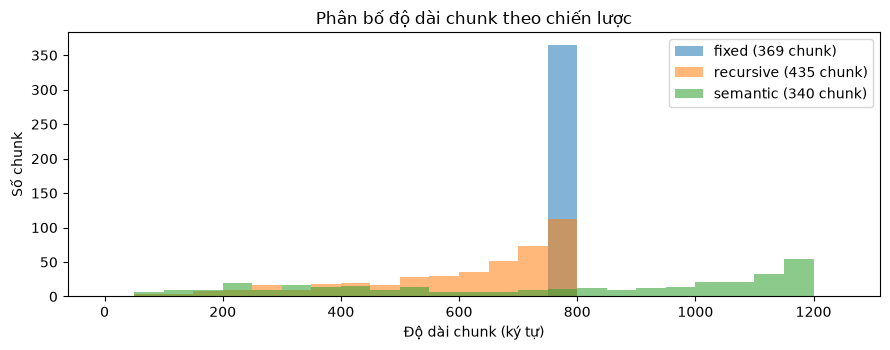

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(0, 1300, 50)
for s, ch in chunks_by.items():
    ax.hist([len(c.text) for c in ch], bins=bins, alpha=0.55, label=f"{s} ({len(ch)} chunk)")
ax.set_xlabel("Độ dài chunk (ký tự)"); ax.set_ylabel("Số chunk"); ax.set_title("Phân bố độ dài chunk theo chiến lược")
ax.legend(); plt.tight_layout(); plt.show()

**Nhận xét:** Fixed-size gần như mọi chunk đều dài đúng 800 ký tự (cắt cứng, kể cả giữa câu). Recursive có nhiều
chunk ngắn hơn vì dừng ở ranh giới đoạn/mục. Semantic có độ dài phân tán nhất (200-1200) vì cắt theo nội dung.

Mỗi chunk lưu đủ các trường mà đề yêu cầu (`chunk_id, text, source, page, section, strategy`) cùng metadata
tài liệu để hiển thị citation:

In [ ]:
c = next(c for c in chunks_by["semantic"] if c.source.startswith("2304") and c.section.startswith("4.2"))
sample = c.to_dict()
sample["text"] = sample["text"][:200] + " ..."
sample["metadata"] = {k: sample["metadata"][k] for k in ["title", "authors", "year", "venue", "doi_url", "short_ref"]}
sample

{'chunk_id': 155,
 'text': '4.2. Efficient Hybrid Encoder\n\nComputational bottleneck analysis. The introduction of multi-scale features accelerates training convergence and improves performance [45]. However, although the deforma ...',
 'source': '2304.08069v3.pdf',
 'page': 4,
 'end_page': 4,
 'section': '4.2. Efficient Hybrid Encoder',
 'strategy': 'semantic',
 'char_start': 16083,
 'char_end': 17085,
 'metadata': {'title': 'DETRs Beat YOLOs on Real-time Object Detection',
  'authors': 'Yian Zhao, Wenyu Lv, Shangliang Xu, Jinman Wei, Guanzhong Wang, Qingqing Dang, Yi Liu, Jie Chen',
  'year': 2023,
  'venue': 'CVPR 2024',
  'doi_url': 'https://arxiv.org/abs/2304.08069',
  'short_ref': 'RT-DETR, Zhao et al., 2023'}}

## Bước 4. Embedding

- Mô hình: **`intfloat/multilingual-e5-base`** (SentenceTransformer, 768 chiều, tối đa 512 token).
- Lý do chọn: câu hỏi bằng **tiếng Việt**, tài liệu bằng **tiếng Anh** → cần mô hình **đa ngôn ngữ** để câu hỏi tiếng
  Việt và đoạn văn tiếng Anh cùng nghĩa nằm gần nhau trong không gian vector.
- Mô hình E5 yêu cầu tiền tố: `"query: "` cho câu hỏi và `"passage: "` cho chunk.
- Vector được chuẩn hóa L2 → tích vô hướng = cosine similarity.
- **Cùng một mô hình** dùng cho cả chunk và câu hỏi (yêu cầu 3.3).

In [ ]:
emb = pipe.embedder
query = "Efficient Hybrid Encoder của RT-DETR gồm AIFI và CCFF có vai trò gì?"
qvec = emb.encode_query(query)
print("Số chiều vector:", qvec.shape[1], "| độ dài (chuẩn L2):", round(float(np.linalg.norm(qvec)), 4))

passages = {
    "RT-DETR 4.2 Efficient Hybrid Encoder": c.text,
    "YOLOv9 - Information Bottleneck": next(x.text for x in chunks_by["semantic"] if "Information Bottleneck" in x.section),
    "DETR - Acknowledgements": next(x.text for x in chunks_by["semantic"] if x.source.startswith("2005") and "Acknowledg" in x.section),
}
pvecs = emb.encode_passages(list(passages.values()))
pd.DataFrame({"đoạn văn": list(passages), "cosine với câu hỏi": (pvecs @ qvec[0]).round(4)})

Số chiều vector: 768 | độ dài (chuẩn L2): 1.0


,đoạn văn,cosine với câu hỏi
0,RT-DETR 4.2 Efficient Hybrid Encoder,0.8128
1,YOLOv9 - Information Bottleneck,0.7227
2,DETR - Acknowledgements,0.7512


Đoạn đúng chủ đề (Efficient Hybrid Encoder) có cosine cao nhất dù câu hỏi viết bằng tiếng Việt → mô hình đa ngôn ngữ
hoạt động đúng mục đích.

*Lưu ý:* với họ mô hình E5, cosine giữa hai văn bản bất kỳ thường nằm trong khoảng 0.7-0.9 (kể cả khi không liên quan),
nên giá trị tuyệt đối ít ý nghĩa - điều quan trọng là **thứ tự**: đoạn liên quan luôn xếp trên đoạn không liên quan.
FAISS chỉ dùng thứ tự này để lấy Top-N.

## Bước 5. BM25 (keyword search) và FAISS (semantic search)

| | BM25 | FAISS |
|---|---|---|
| Kiểu tìm | Khớp **từ khóa** | Khớp **ngữ nghĩa** (vector) |
| Cài đặt | `rank_bm25.BM25Okapi`, `k1 = 1.5`, `b = 0.75`, tách từ đơn giản + bỏ stopword Anh/Việt | `IndexIDMap2(IndexFlatIP)` - tìm chính xác (exhaustive) bằng inner product |
| Mạnh khi | Câu hỏi chứa đúng thuật ngữ: "AIFI", "E-ELAN", "PGI" | Câu hỏi diễn đạt lại, khác ngôn ngữ với tài liệu |

**Ràng buộc của đề:** BM25 và FAISS dùng **cùng một tập chunk và cùng hệ thống `chunk_id`** - FAISS dùng
`IndexIDMap2` để lưu chính `chunk_id` làm ID của vector. Kiểm tra:

In [ ]:
import faiss
for s, r in retrievers.items():
    faiss_ids = set(faiss.vector_to_array(r.faiss.index.id_map).tolist())   # chunk_id lưu trong FAISS
    print(f"{s:9s}: {len(r.chunks)} chunk | BM25 có {len(r.bm25.ids)} id | FAISS có {r.faiss.size} vector | "
          f"id BM25 == id chunk: {set(r.bm25.ids) == set(r.chunks)} | id FAISS == id chunk: {faiss_ids == set(r.chunks)}")

fixed    : 369 chunk | BM25 có 369 id | FAISS có 369 vector | id BM25 == id chunk: True | id FAISS == id chunk: True
recursive: 435 chunk | BM25 có 435 id | FAISS có 435 vector | id BM25 == id chunk: True | id FAISS == id chunk: True
semantic : 340 chunk | BM25 có 340 id | FAISS có 340 vector | id BM25 == id chunk: True | id FAISS == id chunk: True


In [ ]:
retr = retrievers["semantic"]
N = cfg["retrieval"]["bm25_top_n"]                     # 8
bm25_hits = retr.bm25.search(query, N)
faiss_hits = retr.faiss.search(emb.encode_query(query), N)

def show(hits, score_name):
    return pd.DataFrame([{"hạng": i, "chunk_id": cid, score_name: round(sc, 3), "tài liệu": retr.chunks[cid].metadata.get("short_ref"),
                          "trang": retr.chunks[cid].page, "section": retr.chunks[cid].section[:45]}
                         for i, (cid, sc) in enumerate(hits, 1)])

print("CÂU HỎI:", query, "\n\nBM25 Top-8:")
display(show(bm25_hits, "điểm BM25"))
print("FAISS Top-8:")
display(show(faiss_hits, "cosine"))

CÂU HỎI: Efficient Hybrid Encoder của RT-DETR gồm AIFI và CCFF có vai trò gì? 

BM25 Top-8:


,hạng,chunk_id,điểm BM25,tài liệu,trang,section
0,1,158,22.825,"RT-DETR, Zhao et al., 2023",5,4.2. Efficient Hybrid Encoder
1,2,152,20.669,"RT-DETR, Zhao et al., 2023",4,3.2. End-to-end Speed Benchmark
2,3,181,17.873,"RT-DETR, Zhao et al., 2023",11,1. Experimental Settings
3,4,157,17.488,"RT-DETR, Zhao et al., 2023",4,4.2. Efficient Hybrid Encoder
4,5,154,14.819,"RT-DETR, Zhao et al., 2023",4,4.1. Model Overview
5,6,159,14.374,"RT-DETR, Zhao et al., 2023",5,4.2. Efficient Hybrid Encoder
6,7,178,12.512,"RT-DETR, Zhao et al., 2023",8,7. Conclusion
7,8,139,11.718,"RT-DETR, Zhao et al., 2023",2,1. Introduction


FAISS Top-8:


,hạng,chunk_id,cosine,tài liệu,trang,section
0,1,158,0.873,"RT-DETR, Zhao et al., 2023",5,4.2. Efficient Hybrid Encoder
1,2,181,0.850,"RT-DETR, Zhao et al., 2023",11,1. Experimental Settings
2,3,157,0.846,"RT-DETR, Zhao et al., 2023",4,4.2. Efficient Hybrid Encoder
3,4,139,0.833,"RT-DETR, Zhao et al., 2023",2,1. Introduction
4,5,152,0.824,"RT-DETR, Zhao et al., 2023",4,3.2. End-to-end Speed Benchmark
5,6,154,0.824,"RT-DETR, Zhao et al., 2023",4,4.1. Model Overview
6,7,159,0.821,"RT-DETR, Zhao et al., 2023",5,4.2. Efficient Hybrid Encoder
7,8,133,0.820,"RT-DETR, Zhao et al., 2023",1,


## Bước 6. Hợp nhất bằng Reciprocal Rank Fusion (RRF)

$$\text{RRF}(d) = \sum_{r \in \{\text{BM25},\, \text{FAISS}\}} \frac{1}{k + \text{rank}_r(d)}, \qquad k = 60$$

- Chỉ dùng **thứ hạng**, không dùng điểm gốc → không cần chuẩn hóa điểm BM25 (0..∞) và cosine (-1..1) về cùng thang.
- Chunk xuất hiện ở **cả hai** danh sách được cộng điểm hai lần → được ưu tiên.
- Hợp nhất theo **`chunk_id`**: cùng một chunk ở BM25 và FAISS được nhận ra là một.
- `k = 60` là giá trị gốc của Cormack et al. (2009), làm "phẳng" chênh lệch giữa các hạng đầu.

Cấu hình: **BM25 Top-8 + FAISS Top-8 → RRF → Top-5** (theo cấu hình tham khảo của đề).

In [ ]:
k = cfg["retrieval"]["rrf_k"]
fused = reciprocal_rank_fusion({"bm25": [c for c, _ in bm25_hits], "faiss": [c for c, _ in faiss_hits]}, k=k)

rrf_table = pd.DataFrame([{
    "hạng RRF": i, "chunk_id": cid, "hạng BM25": ranks.get("bm25", "-"), "hạng FAISS": ranks.get("faiss", "-"),
    "cách tính": " + ".join(f"1/({k}+{r})" for r in ranks.values()), "điểm RRF": round(score, 5),
    "tài liệu": retr.chunks[cid].metadata.get("short_ref"), "trang": retr.chunks[cid].page,
    "section": retr.chunks[cid].section[:40],
} for i, (cid, score, ranks) in enumerate(fused, 1)])
rrf_table

,hạng RRF,chunk_id,hạng BM25,hạng FAISS,cách tính,điểm RRF,tài liệu,trang,section
0,1,158,1,1,1/(60+1) + 1/(60+1),0.03279,"RT-DETR, Zhao et al., 2023",5,4.2. Efficient Hybrid Encoder
1,2,181,3,2,1/(60+3) + 1/(60+2),0.03200,"RT-DETR, Zhao et al., 2023",11,1. Experimental Settings
2,3,152,2,5,1/(60+2) + 1/(60+5),0.03151,"RT-DETR, Zhao et al., 2023",4,3.2. End-to-end Speed Benchmark
3,4,157,4,3,1/(60+4) + 1/(60+3),0.03150,"RT-DETR, Zhao et al., 2023",4,4.2. Efficient Hybrid Encoder
4,5,154,5,6,1/(60+5) + 1/(60+6),0.03054,"RT-DETR, Zhao et al., 2023",4,4.1. Model Overview
5,6,139,8,4,1/(60+8) + 1/(60+4),0.03033,"RT-DETR, Zhao et al., 2023",2,1. Introduction
6,7,159,6,7,1/(60+6) + 1/(60+7),0.03008,"RT-DETR, Zhao et al., 2023",5,4.2. Efficient Hybrid Encoder
7,8,178,7,-,1/(60+7),0.01493,"RT-DETR, Zhao et al., 2023",8,7. Conclusion
8,9,133,-,8,1/(60+8),0.01471,"RT-DETR, Zhao et al., 2023",1,


In [ ]:
top_k = cfg["retrieval"]["top_k"]
final = retr.search(query, mode="hybrid", top_k=top_k)          # đúng hàm mà ứng dụng web gọi
assert [r.chunk.chunk_id for r in final.results] == [cid for cid, _, _ in fused[:top_k]]
print(f"Top-{top_k} đưa vào context cho LLM (khớp với bảng RRF ở trên):")
for r in final.results:
    print(f"  [{r.rank}] chunk {r.chunk.chunk_id:4d} | {r.chunk.metadata['short_ref']}, {r.chunk.section}, trang {r.chunk.page}")
print("\nThời gian truy vấn (ms):", {k_: round(v, 1) for k_, v in final.timings_ms.items()})

Top-5 đưa vào context cho LLM (khớp với bảng RRF ở trên):
  [1] chunk  158 | RT-DETR, Zhao et al., 2023, 4.2. Efficient Hybrid Encoder, trang 5
  [2] chunk  181 | RT-DETR, Zhao et al., 2023, 1. Experimental Settings, trang 11
  [3] chunk  152 | RT-DETR, Zhao et al., 2023, 3.2. End-to-end Speed Benchmark, trang 4
  [4] chunk  157 | RT-DETR, Zhao et al., 2023, 4.2. Efficient Hybrid Encoder, trang 4
  [5] chunk  154 | RT-DETR, Zhao et al., 2023, 4.1. Model Overview, trang 4

Thời gian truy vấn (ms): {'bm25': 1.1, 'embed_query': 44.1, 'faiss': 4.9, 'rrf': 0.0, 'total': 50.2}


## Bước 7. Đánh giá

**Bộ câu hỏi** (`eval/questions.csv`): 15 câu - 5 khớp từ khóa (`keyword`), 5 diễn đạt lại (`semantic`),
5 tổng hợp nhiều nguồn (`synthesis`, trong đó 3 câu so sánh phương pháp). Mỗi câu có ground truth `file:trang` và mục.

**Cách xác định chunk liên quan:** chunk được coi là đúng nếu cùng file và khoảng trang của chunk giao với trang ground truth.

**Metrics** (k = 3):
- **Precision@3**: tỉ lệ chunk đúng trong Top-3.
- **Recall@3**: tỉ lệ vị trí ground truth (file:trang) được Top-3 bao phủ.
- **Hit@3**: có ít nhất 1 chunk đúng trong Top-3 hay không.
- **MRR**: nghịch đảo hạng của chunk đúng đầu tiên (tính trên Top-10).
- **nDCG@3**: chất lượng xếp hạng, ưu tiên chunk đúng ở hạng cao.
- **Thời gian truy vấn** (ms).

Đánh giá 3 chiến lược chunking × 3 chế độ tìm kiếm (BM25, FAISS, Hybrid) = 9 cấu hình.

In [ ]:
questions = pd.read_csv(resolve_path(cfg["paths"]["eval_questions"]), encoding="utf-8-sig", dtype=str, keep_default_na=False)
print(questions["type"].value_counts().to_dict())
questions[["id", "type", "query", "ground_truth", "gt_section"]]

{'keyword': 5, 'semantic': 5, 'synthesis': 5}


,id,type,query,ground_truth,gt_section
0,Q01,keyword,E-ELAN trong YOLOv7 là gì và nó thay đổi kiến trúc ELAN như thế nào?,2207.02696v1.pdf:3,YOLOv7 §3.1 Extended efficient layer aggregation networks
1,Q02,keyword,Programmable Gradient Information (PGI) gồm những thành phần nào?,2402.13616v2.pdf:5,YOLOv9 §4.1 Programmable Gradient Information
2,Q03,keyword,Efficient Hybrid Encoder của RT-DETR gồm AIFI và CCFF có vai trò gì?,2304.08069v3.pdf:4-5,RT-DETR §4.2 Efficient Hybrid Encoder
3,Q04,keyword,Consistent matching metric trong YOLOv10 được định nghĩa như thế nào?,2405.14458v2.pdf:4,YOLOv10 §3.1 Consistent Dual Assignments for NMS-free Training
4,Q05,keyword,DETR dùng Hungarian algorithm để làm gì trong hàm loss?,2005.12872v3.pdf:5-6,DETR §3.1 Object detection set prediction loss
5,Q06,semantic,Vì sao dữ liệu đầu vào bị mất dần thông tin khi đi qua nhiều lớp của mạng nơ-ron sâu?,2402.13616v2.pdf:2-4,"YOLOv9 §1 Introduction, §3.1 Information Bottleneck Principle"
6,Q07,semantic,Làm thế nào để chọn được các truy vấn khởi tạo chất lượng tốt hơn cho bộ giải mã của d...,2304.08069v3.pdf:5,RT-DETR §4.3 Uncertainty-minimal Query Selection
7,Q08,semantic,Mô hình phát hiện đối tượng dùng Transformer đầu tiên hoạt động kém với loại vật thể nào?,"2005.12872v3.pdf:2,9,17","DETR §1 Introduction, §4.1 Comparison with Faster R-CNN, §5 Conclusion"
8,Q09,semantic,Bước hậu xử lý loại bỏ các khung hình chồng lấn ảnh hưởng thế nào tới tốc độ suy luận?,2304.08069v3.pdf:3,RT-DETR §3.1 Analysis of NMS
9,Q10,semantic,Làm sao dùng một nhánh dự đoán phụ để hỗ trợ huấn luyện mà không làm tăng chi phí khi ...,2207.02696v1.pdf:5,YOLOv7 §4.2 Coarse for auxiliary and fine for lead loss


In [ ]:
tables = evaluate(cfg, pipeline=pipe)                 # chỉ retrieval, không gọi LLM
summary = tables["summary"]
summary

,strategy,mode,precision@3,recall@3,hit@3,mrr,ndcg@3,latency_ms
0,fixed,bm25,0.289,0.456,0.600,0.419,0.286,1.380
1,fixed,faiss,0.378,0.556,0.667,0.530,0.372,49.053
2,fixed,hybrid,0.378,0.622,0.733,0.640,0.412,48.827
3,recursive,bm25,0.289,0.433,0.533,0.391,0.271,2.000
4,recursive,faiss,0.311,0.589,0.733,0.439,0.295,67.967
5,recursive,hybrid,0.333,0.533,0.600,0.509,0.333,66.160
6,semantic,bm25,0.222,0.422,0.533,0.460,0.251,1.760
7,semantic,faiss,0.378,0.656,0.800,0.686,0.416,62.687
8,semantic,hybrid,0.378,0.689,0.800,0.644,0.400,65.033


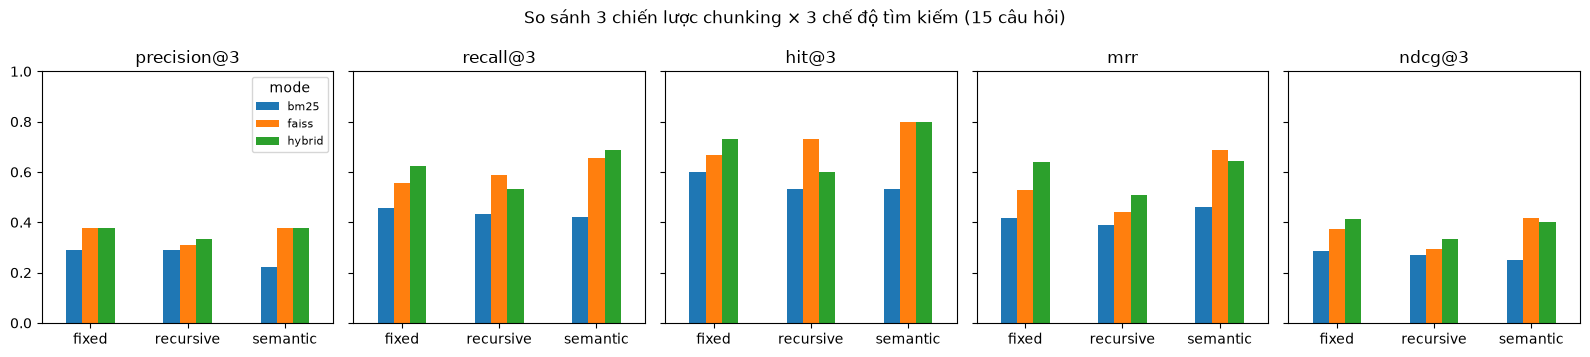

In [ ]:
metrics = ["precision@3", "recall@3", "hit@3", "mrr", "ndcg@3"]
fig, axes = plt.subplots(1, len(metrics), figsize=(16, 3.6), sharey=True)
for ax, m in zip(axes, metrics):
    pv = summary.pivot(index="strategy", columns="mode", values=m)[["bm25", "faiss", "hybrid"]]
    pv.plot.bar(ax=ax, rot=0, legend=(m == metrics[0]))
    ax.set_title(m); ax.set_xlabel(""); ax.set_ylim(0, 1)
axes[0].legend(title="mode", fontsize=8)
plt.suptitle("So sánh 3 chiến lược chunking × 3 chế độ tìm kiếm (15 câu hỏi)"); plt.tight_layout(); plt.show()

In [ ]:
# Kết quả theo loại câu hỏi (chế độ hybrid)
by_type = tables["summary_by_type"]
by_type[by_type["mode"] == "hybrid"].pivot(index="type", columns="strategy", values=["recall@3", "hit@3"]).round(3)

recall@3                    hit@3                   
strategy     fixed recursive semantic fixed recursive semantic
type                                                          
keyword      1.000       1.0    0.800   1.0       1.0      0.8
semantic     0.600       0.4    0.800   0.6       0.4      0.8
synthesis    0.267       0.2    0.467   0.6       0.4      0.8

In [ ]:
# Câu hỏi mà các chiến lược cho kết quả khác nhau rõ rệt (hybrid, Hit@3)
pq = tables["per_query"]
hit = pq[pq["mode"] == "hybrid"].pivot(index="id", columns="strategy", values="hit@3")
diff = hit[hit.max(axis=1) != hit.min(axis=1)]
diff.join(questions.set_index("id")["query"])

,fixed,recursive,semantic,query
id,,,,
Q04,1.0,1.0,0.0,Consistent matching metric trong YOLOv10 được định nghĩa như thế nào?
Q08,1.0,0.0,1.0,Mô hình phát hiện đối tượng dùng Transformer đầu tiên hoạt động kém với loại vật thể nào?
Q10,0.0,0.0,1.0,Làm sao dùng một nhánh dự đoán phụ để hỗ trợ huấn luyện mà không làm tăng chi phí khi ...
Q12,1.0,0.0,1.0,"So sánh độ chính xác AP trên COCO của YOLOv7, YOLOv9 và RT-DETR."
Q14,0.0,0.0,1.0,YOLOv7 và YOLOv9 phát triển kiến trúc ELAN theo những hướng nào?


In [ ]:
# Câu hỏi thất bại với cấu hình mặc định (semantic + hybrid): không có chunk đúng nào trong Top-3
fail = pq[(pq["strategy"] == "semantic") & (pq["mode"] == "hybrid") & (pq["hit@3"] == 0)]
fail[["id", "type", "query", "top3", "ground_truth"]]

,id,type,query,top3,ground_truth
101,Q04,keyword,Consistent matching metric trong YOLOv10 được định nghĩa như thế nào?,2405.14458v2.pdf:8-9 | 2405.14458v2.pdf:20-21 | 2405.14458v2.pdf:5,2405.14458v2.pdf:4
110,Q07,semantic,Làm thế nào để chọn được các truy vấn khởi tạo chất lượng tốt hơn cho bộ giải mã của d...,2304.08069v3.pdf:2 | 2304.08069v3.pdf:2 | 2304.08069v3.pdf:1,2304.08069v3.pdf:5
134,Q15,synthesis,Các tác giả RT-DETR và YOLOv10 thừa nhận những hạn chế gì trong nghiên cứu của mình?,2405.14458v2.pdf:7 | 2405.14458v2.pdf:8 | 2405.14458v2.pdf:1-2,"2304.08069v3.pdf:8; 2405.14458v2.pdf:9,21"


## Tóm tắt

- **Dữ liệu:** 5 bài báo, 94 trang; đọc theo trang, làm sạch, bỏ References, giữ Phụ lục.
- **Chunking:** Fixed-size (baseline), Recursive, Semantic; mỗi chunk có `chunk_id, text, source, page, section, strategy`.
- **Retrieval:** Hybrid Search - BM25 Top-8 + FAISS Top-8 (cùng `chunk_id`) → RRF (k = 60) → Top-5.
- **Đánh giá:** 15 câu hỏi, 9 cấu hình; cấu hình mặc định của ứng dụng (`semantic + hybrid`) được chọn theo Recall@3
  và Hit@3 cao nhất ở bảng trên.
- Kết quả chi tiết từng câu: `eval/results/eval_latest.xlsx` (tạo bằng `python -m rag.evaluation.run_eval`).
- Đánh giá chất lượng câu trả lời của LLM: `python -m rag.evaluation.run_eval --with-llm` (sheet `answers`, chấm tay).